# Statistical Evaluation - Global Score versus Path-based Structural Importance

This notebook performs the complete statistical evaluation of the proposed ranking
framework. It contains no feature-attribution benchmark. The compared strategies are:

- Global Score;
- Path-based Structural Importance, lambda = 0.25;
- Path-based Structural Importance, lambda = 0.50;
- Path-based Structural Importance, lambda = 0.75.

The analysis follows the predictive-simulation outputs defined by the framework:
customer-level $\Delta P$, mean risk reduction, threshold crossing, the empirical
distribution of $\Delta P$, and 95% bootstrap confidence intervals. Results are
reported separately for TP, FP, and the complete TP+FP high-risk cohort.


## 0. Imports and configuration

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon, friedmanchisquare, binomtest
from openpyxl import load_workbook
from openpyxl.styles import Font, PatternFill, Alignment

INPUT_XLSX = Path("Telco_GlobalScore_vs_PathStructural_Intervention_Results.xlsx")
OUTPUT_XLSX = Path("Telco_GlobalScore_vs_PathStructural_Statistical_Evaluation.xlsx")
FIGURE_DIR = Path("Telco_Ranking_Comparison_Figures")
FIGURE_DIR.mkdir(exist_ok=True)

MODEL_ORDER = ["XGBoost", "RandomForest", "GBM", "CatBoost"]
SCENARIO_ORDER = ["HIGH", "HIGH+MEDIUM", "HIGH+MEDIUM+LOW"]
COHORT_ORDER = ["TP", "FP", "TP+FP"]
STRATEGY_ORDER = [
    "Global Score", "Path Structural lambda=0.25",
    "Path Structural lambda=0.50", "Path Structural lambda=0.75",
]
PATH_STRATEGIES = STRATEGY_ORDER[1:]
COMPARISON_PATH_STRATEGY = "Path Structural lambda=0.75"
N_BOOTSTRAP = 10_000
SEED = 20260928
ALPHA = 0.05

if not INPUT_XLSX.exists():
    raise FileNotFoundError(f"Missing {INPUT_XLSX}; run notebook 01 first")


## 1. Load customer-level results and construct the three cohorts

Every row in `Customer Level` belongs to the baseline predicted-positive cohort.
`Baseline_Group` identifies TP or FP. TP+FP is constructed by retaining both groups.
The same customer identifiers must be present for all ranking strategies within each
Model x Scenario comparison; this pairing is verified before inference.


In [2]:
customer = pd.read_excel(INPUT_XLSX, sheet_name="Customer Level")
required = {
    "CustomerID", "Strategy", "Model", "Scenario", "Baseline_Group",
    "P_Churn_Before", "P_Churn_After", "Delta_P_Churn", "Threshold_Crossed",
    "Effective_Delta_P_Positive", "Worsened_Delta_P_Negative",
}
missing = required.difference(customer.columns)
if missing:
    raise KeyError(f"Customer Level missing columns: {sorted(missing)}")

customer["Threshold_Crossed_Bool"] = customer["Threshold_Crossed"].astype(str).str.upper().eq("YES")
customer["Effective_Bool"] = customer["Effective_Delta_P_Positive"].astype(str).str.upper().eq("YES")
customer["Worsened_Bool"] = customer["Worsened_Delta_P_Negative"].astype(str).str.upper().eq("YES")

cohort_frames = []
for cohort in COHORT_ORDER:
    part = customer.copy() if cohort == "TP+FP" else customer[customer["Baseline_Group"] == cohort].copy()
    part["Cohort"] = cohort
    cohort_frames.append(part)
analysis_df = pd.concat(cohort_frames, ignore_index=True)

pair_keys = ["CustomerID", "Model", "Scenario", "Cohort"]
for model in MODEL_ORDER:
    for scenario in SCENARIO_ORDER:
        for cohort in COHORT_ORDER:
            reference = set(analysis_df[(analysis_df.Strategy == "Global Score") & (analysis_df.Model == model) & (analysis_df.Scenario == scenario) & (analysis_df.Cohort == cohort)].CustomerID)
            for strategy in PATH_STRATEGIES:
                candidate = set(analysis_df[(analysis_df.Strategy == strategy) & (analysis_df.Model == model) & (analysis_df.Scenario == scenario) & (analysis_df.Cohort == cohort)].CustomerID)
                if reference != candidate:
                    raise ValueError(f"Pairing mismatch: {strategy}, {model}, {scenario}, {cohort}")

print("Analysis rows:", len(analysis_df))


Analysis rows: 29592


## 2. Statistical framework

For each Strategy x Model x Scenario x Cohort combination, the following are computed:

- mean and median $\Delta P$;
- minimum, Q1, median, Q3, and maximum of $\Delta P$;
- effectiveness rate, $(\Delta P>0)$;
- threshold-crossing rate, $P(\hat Y_{after}=0\mid\hat Y_{before}=1)$;
- worsened rate, $(\Delta P<0)$;
- non-parametric percentile-bootstrap 95% confidence intervals for mean $\Delta P$,
  effectiveness, and threshold crossing.

For a sample of size $n$, each bootstrap replicate draws $n$ observations with
replacement from the original customer-level sample. With $B=10{,}000$ replicates,
the 2.5th and 97.5th percentiles of the bootstrap distribution form the 95% interval:

$$
CI_{95\%}=[Q_{0.025}(\hat\theta^*),Q_{0.975}(\hat\theta^*)].
$$

These intervals describe uncertainty from the evaluated test cohort. 


In [3]:
rng = np.random.default_rng(SEED)

def bootstrap_ci(values, statistic=np.mean, n_boot=N_BOOTSTRAP):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]
    if len(x) == 0:
        return np.nan, np.nan
    estimates = np.empty(n_boot)
    for b in range(n_boot):
        estimates[b] = statistic(rng.choice(x, size=len(x), replace=True))
    return tuple(np.quantile(estimates, [0.025, 0.975]))

descriptive_rows = []
for strategy in STRATEGY_ORDER:
    for model in MODEL_ORDER:
        for scenario in SCENARIO_ORDER:
            for cohort in COHORT_ORDER:
                g = analysis_df[(analysis_df.Strategy == strategy) & (analysis_df.Model == model) & (analysis_df.Scenario == scenario) & (analysis_df.Cohort == cohort)]
                delta = g["Delta_P_Churn"].to_numpy(float)
                crossing = g["Threshold_Crossed_Bool"].to_numpy(float)
                effective = g["Effective_Bool"].to_numpy(float)
                q = np.quantile(delta, [0, .25, .5, .75, 1]) if len(delta) else [np.nan] * 5
                mean_lo, mean_hi = bootstrap_ci(delta)
                cross_lo, cross_hi = bootstrap_ci(crossing)
                eff_lo, eff_hi = bootstrap_ci(effective)
                descriptive_rows.append({
                    "Strategy": strategy, "Model": model, "Scenario": scenario, "Cohort": cohort, "N": len(g),
                    "Min_Delta_P": q[0], "Q1_Delta_P": q[1], "Median_Delta_P": q[2],
                    "Q3_Delta_P": q[3], "Max_Delta_P": q[4], "Mean_Delta_P": np.mean(delta),
                    "Mean_Delta_P_CI95_Lower": mean_lo, "Mean_Delta_P_CI95_Upper": mean_hi,
                    "Threshold_Crossing_Rate": crossing.mean(),
                    "Threshold_Crossing_CI95_Lower": cross_lo, "Threshold_Crossing_CI95_Upper": cross_hi,
                    "Effectiveness_Rate": effective.mean(),
                    "Effectiveness_CI95_Lower": eff_lo, "Effectiveness_CI95_Upper": eff_hi,
                    "Worsened_Rate": g["Worsened_Bool"].mean(),
                })

descriptive_df = pd.DataFrame(descriptive_rows)
display(descriptive_df)

# Dedicated TP table matching the established DeltaP Statistics structure.
tp_counts_df = analysis_df[analysis_df["Cohort"].eq("TP")].groupby(
    ["Strategy", "Model", "Scenario"], as_index=False
).agg(
    Rescued_TP_Count=("Threshold_Crossed_Bool", "sum"),
    TP_With_Increased_Predicted_Risk=("Worsened_Bool", "sum"),
)

delta_p_statistics_df = descriptive_df[
    descriptive_df["Cohort"].eq("TP")
][[
    "Strategy", "Model", "Scenario", "N",
    "Min_Delta_P", "Q1_Delta_P", "Median_Delta_P", "Q3_Delta_P", "Max_Delta_P",
    "Mean_Delta_P", "Mean_Delta_P_CI95_Lower", "Mean_Delta_P_CI95_Upper",
    "Threshold_Crossing_Rate", "Threshold_Crossing_CI95_Lower",
    "Threshold_Crossing_CI95_Upper",
]].rename(columns={
    "N": "TP_N",
    "Threshold_Crossing_Rate": "Rescue_Rate",
    "Threshold_Crossing_CI95_Lower": "Rescue_Rate_CI95_Lower",
    "Threshold_Crossing_CI95_Upper": "Rescue_Rate_CI95_Upper",
}).merge(
    tp_counts_df, on=["Strategy", "Model", "Scenario"], how="left", validate="one_to_one"
)

delta_p_statistics_df = delta_p_statistics_df[[
    "Strategy", "Model", "Scenario", "TP_N",
    "Min_Delta_P", "Q1_Delta_P", "Median_Delta_P", "Q3_Delta_P", "Max_Delta_P",
    "Mean_Delta_P", "Mean_Delta_P_CI95_Lower", "Mean_Delta_P_CI95_Upper",
    "Rescued_TP_Count", "Rescue_Rate", "Rescue_Rate_CI95_Lower",
    "Rescue_Rate_CI95_Upper", "TP_With_Increased_Predicted_Risk",
]].sort_values(["Strategy", "Model", "Scenario"]).reset_index(drop=True)

display(delta_p_statistics_df)


,Strategy,Model,Scenario,Cohort,N,Min_Delta_P,Q1_Delta_P,Median_Delta_P,Q3_Delta_P,Max_Delta_P,Mean_Delta_P,Mean_Delta_P_CI95_Lower,Mean_Delta_P_CI95_Upper,Threshold_Crossing_Rate,Threshold_Crossing_CI95_Lower,Threshold_Crossing_CI95_Upper,Effectiveness_Rate,Effectiveness_CI95_Lower,Effectiveness_CI95_Upper,Worsened_Rate
0,Global Score,XGBoost,HIGH,TP,185,0.172938,0.301013,0.351278,0.419522,0.527799,0.359595,0.348012,0.371065,0.886486,0.837838,0.929730,1.0,1.0,1.0,0.0
1,Global Score,XGBoost,HIGH,FP,122,0.076464,0.262757,0.321732,0.392362,0.531492,0.326706,0.311258,0.342240,0.975410,0.942623,1.000000,1.0,1.0,1.0,0.0
2,Global Score,XGBoost,HIGH,TP+FP,307,0.076464,0.285311,0.335864,0.408333,0.531492,0.346525,0.337040,0.355876,0.921824,0.889251,0.951140,1.0,1.0,1.0,0.0
3,Global Score,XGBoost,HIGH+MEDIUM,TP,185,0.165732,0.333193,0.401372,0.464173,0.564719,0.398868,0.386076,0.411542,0.945946,0.913514,0.978378,1.0,1.0,1.0,0.0
4,Global Score,XGBoost,HIGH+MEDIUM,FP,122,0.095932,0.287469,0.338502,0.433086,0.562518,0.359760,0.342430,0.377455,1.000000,1.000000,1.000000,1.0,1.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,Path Structural lambda=0.75,CatBoost,HIGH+MEDIUM,FP,118,0.114588,0.329082,0.381765,0.459399,0.580572,0.392402,0.376313,0.408737,0.991525,0.974576,1.000000,1.0,1.0,1.0,0.0
140,Path Structural lambda=0.75,CatBoost,HIGH+MEDIUM,TP+FP,300,0.114588,0.346783,0.422924,0.491752,0.589485,0.419452,0.409405,0.429506,0.970000,0.950000,0.986667,1.0,1.0,1.0,0.0
141,Path Structural lambda=0.75,CatBoost,HIGH+MEDIUM+LOW,TP,182,0.218314,0.380334,0.477119,0.537888,0.638624,0.462945,0.449243,0.476276,0.989011,0.972527,1.000000,1.0,1.0,1.0,0.0
142,Path Structural lambda=0.75,CatBoost,HIGH+MEDIUM+LOW,FP,118,0.176527,0.345681,0.391923,0.483710,0.626840,0.412465,0.395948,0.428956,1.000000,1.000000,1.000000,1.0,1.0,1.0,0.0


,Strategy,Model,Scenario,TP_N,Min_Delta_P,Q1_Delta_P,Median_Delta_P,Q3_Delta_P,Max_Delta_P,Mean_Delta_P,Mean_Delta_P_CI95_Lower,Mean_Delta_P_CI95_Upper,Rescued_TP_Count,Rescue_Rate,Rescue_Rate_CI95_Lower,Rescue_Rate_CI95_Upper,TP_With_Increased_Predicted_Risk
0,Global Score,CatBoost,HIGH,182,0.213299,0.335380,0.390686,0.435072,0.512820,0.382789,0.373127,0.392351,159,0.873626,0.824176,0.917582,0
1,Global Score,CatBoost,HIGH+MEDIUM,182,0.232644,0.378415,0.446133,0.504781,0.589485,0.438086,0.425826,0.449957,174,0.956044,0.923077,0.983516,0
2,Global Score,CatBoost,HIGH+MEDIUM+LOW,182,0.218314,0.380334,0.477119,0.537888,0.638624,0.462945,0.449561,0.476532,180,0.989011,0.972527,1.000000,0
3,Global Score,GBM,HIGH,191,0.171673,0.266396,0.359665,0.395194,0.418781,0.337819,0.328234,0.347393,146,0.764398,0.701571,0.821990,0
4,Global Score,GBM,HIGH+MEDIUM,191,0.051004,0.353681,0.425981,0.478232,0.516674,0.405840,0.393476,0.417820,172,0.900524,0.858639,0.942408,0
5,Global Score,GBM,HIGH+MEDIUM+LOW,191,0.069245,0.358201,0.448434,0.501320,0.574617,0.424706,0.410586,0.438232,182,0.952880,0.921466,0.979058,0
6,Global Score,RandomForest,HIGH,185,0.129142,0.274523,0.363997,0.435945,0.577377,0.360234,0.344804,0.375433,178,0.962162,0.929730,0.989189,0
7,Global Score,RandomForest,HIGH+MEDIUM,185,0.129142,0.306997,0.376177,0.441989,0.589750,0.373622,0.358841,0.388087,183,0.989189,0.972973,1.000000,0
8,Global Score,RandomForest,HIGH+MEDIUM+LOW,185,0.180238,0.317729,0.385253,0.452778,0.657125,0.396117,0.380600,0.411991,185,1.000000,1.000000,1.000000,0
9,Global Score,XGBoost,HIGH,185,0.172938,0.301013,0.351278,0.419522,0.527799,0.359595,0.348012,0.371065,164,0.886486,0.837838,0.929730,0


## 3. Paired Global Score versus path-based comparisons

The paired Wilcoxon signed-rank test evaluates customer-level differences in
$\Delta P$. The exact McNemar test evaluates discordant threshold-crossing outcomes.
Both use the same customers under the two ranking strategies.

For each outcome family, Holm correction controls the family-wise error rate across
all Model x Scenario x Cohort x lambda comparisons. A positive mean difference
`Path minus Global` favors the path-based strategy.


In [4]:
def holm_adjust(pvalues):
    p = np.asarray(pvalues, dtype=float)
    order = np.argsort(p)
    adjusted = np.empty_like(p)
    running = 0.0
    m = len(p)
    for rank, idx in enumerate(order):
        running = max(running, min(1.0, (m - rank) * p[idx]))
        adjusted[idx] = running
    return adjusted

def paired_bootstrap_difference(a, b, n_boot=N_BOOTSTRAP):
    d = np.asarray(a, float) - np.asarray(b, float)
    estimates = np.empty(n_boot)
    for i in range(n_boot):
        estimates[i] = rng.choice(d, size=len(d), replace=True).mean()
    return d.mean(), *np.quantile(estimates, [.025, .975])

def rank_biserial(diff):
    d = np.asarray(diff, float)
    d = d[np.abs(d) > 1e-15]
    if len(d) == 0:
        return 0.0
    ranks = pd.Series(np.abs(d)).rank(method="average").to_numpy()
    return float((ranks[d > 0].sum() - ranks[d < 0].sum()) / ranks.sum())

pairwise_rows = []
keys = ["CustomerID", "Model", "Scenario", "Cohort"]
for path_strategy in PATH_STRATEGIES:
    for model in MODEL_ORDER:
        for scenario in SCENARIO_ORDER:
            for cohort in COHORT_ORDER:
                g = analysis_df[(analysis_df.Strategy == "Global Score") & (analysis_df.Model == model) & (analysis_df.Scenario == scenario) & (analysis_df.Cohort == cohort)]
                p = analysis_df[(analysis_df.Strategy == path_strategy) & (analysis_df.Model == model) & (analysis_df.Scenario == scenario) & (analysis_df.Cohort == cohort)]
                pair = g.merge(p, on=keys, suffixes=("_Global", "_Path"), validate="one_to_one")
                dg = pair["Delta_P_Churn_Global"].to_numpy(float)
                dp = pair["Delta_P_Churn_Path"].to_numpy(float)
                diff = dp - dg
                mean_diff, diff_lo, diff_hi = paired_bootstrap_difference(dp, dg)
                if np.any(np.abs(diff) > 1e-15):
                    w = wilcoxon(dp, dg, alternative="two-sided", zero_method="wilcox")
                else:
                    w = None
                w_stat = float(w.statistic) if w is not None else 0.0
                w_p = float(w.pvalue) if w is not None else 1.0
                cg = pair["Threshold_Crossed_Bool_Global"].astype(bool).to_numpy()
                cp = pair["Threshold_Crossed_Bool_Path"].astype(bool).to_numpy()
                path_only = int((cp & ~cg).sum())
                global_only = int((~cp & cg).sum())
                discordant = path_only + global_only
                mc_p = float(binomtest(path_only, discordant, .5).pvalue) if discordant else 1.0
                cross_diff, cross_lo, cross_hi = paired_bootstrap_difference(cp.astype(float), cg.astype(float))
                pairwise_rows.append({
                    "Path_Strategy": path_strategy, "Model": model, "Scenario": scenario, "Cohort": cohort,
                    "Paired_N": len(pair), "Global_Mean_Delta_P": dg.mean(), "Path_Mean_Delta_P": dp.mean(),
                    "Mean_Delta_P_Difference_Path_minus_Global": mean_diff,
                    "Delta_P_Difference_CI95_Lower": diff_lo, "Delta_P_Difference_CI95_Upper": diff_hi,
                    "Wilcoxon_W": w_stat, "Wilcoxon_P_Raw": w_p,
                    "Rank_Biserial_Path_minus_Global": rank_biserial(diff),
                    "Global_Threshold_Crossing_Rate": cg.mean(), "Path_Threshold_Crossing_Rate": cp.mean(),
                    "Crossing_Rate_Difference_Path_minus_Global": cross_diff,
                    "Crossing_Difference_CI95_Lower": cross_lo, "Crossing_Difference_CI95_Upper": cross_hi,
                    "Path_Only_Crossed": path_only, "Global_Only_Crossed": global_only,
                    "Discordant_Pairs": discordant, "McNemar_Exact_P_Raw": mc_p,
                })

pairwise_df = pd.DataFrame(pairwise_rows)
pairwise_df["Wilcoxon_P_Holm"] = holm_adjust(pairwise_df["Wilcoxon_P_Raw"])
pairwise_df["McNemar_Exact_P_Holm"] = holm_adjust(pairwise_df["McNemar_Exact_P_Raw"])
pairwise_df["DeltaP_Significant_Holm"] = pairwise_df["Wilcoxon_P_Holm"] < ALPHA
pairwise_df["Crossing_Significant_Holm"] = pairwise_df["McNemar_Exact_P_Holm"] < ALPHA
display(pairwise_df)


,Path_Strategy,Model,Scenario,Cohort,Paired_N,Global_Mean_Delta_P,Path_Mean_Delta_P,Mean_Delta_P_Difference_Path_minus_Global,Delta_P_Difference_CI95_Lower,Delta_P_Difference_CI95_Upper,...,Crossing_Difference_CI95_Lower,Crossing_Difference_CI95_Upper,Path_Only_Crossed,Global_Only_Crossed,Discordant_Pairs,McNemar_Exact_P_Raw,Wilcoxon_P_Holm,McNemar_Exact_P_Holm,DeltaP_Significant_Holm,Crossing_Significant_Holm
0,Path Structural lambda=0.25,XGBoost,HIGH,TP,185,0.359595,0.359595,0.000000,0.000000,0.000000,...,0.000000,0.0,0,0,0,1.00,1.000000e+00,1.0,False,False
1,Path Structural lambda=0.25,XGBoost,HIGH,FP,122,0.326706,0.326706,0.000000,0.000000,0.000000,...,0.000000,0.0,0,0,0,1.00,1.000000e+00,1.0,False,False
2,Path Structural lambda=0.25,XGBoost,HIGH,TP+FP,307,0.346525,0.346525,0.000000,0.000000,0.000000,...,0.000000,0.0,0,0,0,1.00,1.000000e+00,1.0,False,False
3,Path Structural lambda=0.25,XGBoost,HIGH+MEDIUM,TP,185,0.398868,0.384746,-0.014122,-0.016807,-0.011475,...,-0.037838,0.0,0,3,3,0.25,1.205487e-15,1.0,True,False
4,Path Structural lambda=0.25,XGBoost,HIGH+MEDIUM,FP,122,0.359760,0.345039,-0.014721,-0.017750,-0.011788,...,-0.024590,0.0,0,1,1,1.00,4.304962e-11,1.0,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103,Path Structural lambda=0.75,CatBoost,HIGH+MEDIUM,FP,118,0.392988,0.392402,-0.000586,-0.000817,-0.000372,...,0.000000,0.0,0,0,0,1.00,4.036404e-04,1.0,True,False
104,Path Structural lambda=0.75,CatBoost,HIGH+MEDIUM,TP+FP,300,0.420347,0.419452,-0.000895,-0.001080,-0.000721,...,0.000000,0.0,0,0,0,1.00,2.270366e-14,1.0,True,False
105,Path Structural lambda=0.75,CatBoost,HIGH+MEDIUM+LOW,TP,182,0.462945,0.462945,0.000000,0.000000,0.000000,...,0.000000,0.0,0,0,0,1.00,1.000000e+00,1.0,False,False
106,Path Structural lambda=0.75,CatBoost,HIGH+MEDIUM+LOW,FP,118,0.412465,0.412465,0.000000,0.000000,0.000000,...,0.000000,0.0,0,0,0,1.00,1.000000e+00,1.0,False,False


## 4. Lambda sensitivity analysis

The Friedman test evaluates whether the three lambda settings produce the same paired
customer-level $\Delta P$ distribution. When the omnibus test is significant,
pairwise Wilcoxon tests identify which lambda pairs differ. Holm correction is applied
to the lambda-pair tests.

This is a sensitivity analysis of the path-length penalty, not a causal-effect test.


In [5]:
lambda_rows, lambda_pair_rows = [], []
lambda_pairs = [(PATH_STRATEGIES[0], PATH_STRATEGIES[1]), (PATH_STRATEGIES[0], PATH_STRATEGIES[2]), (PATH_STRATEGIES[1], PATH_STRATEGIES[2])]

for model in MODEL_ORDER:
    for scenario in SCENARIO_ORDER:
        for cohort in COHORT_ORDER:
            wide = None
            for strategy in PATH_STRATEGIES:
                part = analysis_df[(analysis_df.Strategy == strategy) & (analysis_df.Model == model) & (analysis_df.Scenario == scenario) & (analysis_df.Cohort == cohort)][["CustomerID", "Delta_P_Churn"]].rename(columns={"Delta_P_Churn": strategy})
                wide = part if wide is None else wide.merge(part, on="CustomerID", validate="one_to_one")
            arrays = [wide[s].to_numpy(float) for s in PATH_STRATEGIES]
            if all(np.allclose(arrays[0], a) for a in arrays[1:]):
                stat, pvalue = 0.0, 1.0
            else:
                test = friedmanchisquare(*arrays)
                stat, pvalue = float(test.statistic), float(test.pvalue)
            lambda_rows.append({
                "Model": model, "Scenario": scenario, "Cohort": cohort, "N": len(wide),
                "Friedman_ChiSquare": stat, "Friedman_P_Raw": pvalue,
                "Mean_DeltaP_lambda_0.25": arrays[0].mean(),
                "Mean_DeltaP_lambda_0.50": arrays[1].mean(),
                "Mean_DeltaP_lambda_0.75": arrays[2].mean(),
            })
            for a, b in lambda_pairs:
                diff = wide[a].to_numpy(float) - wide[b].to_numpy(float)
                if np.any(np.abs(diff) > 1e-15):
                    test = wilcoxon(wide[a], wide[b], alternative="two-sided", zero_method="wilcox")
                    stat_w, p_w = float(test.statistic), float(test.pvalue)
                else:
                    stat_w, p_w = 0.0, 1.0
                lambda_pair_rows.append({
                    "Model": model, "Scenario": scenario, "Cohort": cohort,
                    "Strategy_A": a, "Strategy_B": b,
                    "Mean_Difference_A_minus_B": diff.mean(), "Wilcoxon_W": stat_w,
                    "Wilcoxon_P_Raw": p_w, "Rank_Biserial_A_minus_B": rank_biserial(diff),
                })

lambda_sensitivity_df = pd.DataFrame(lambda_rows)
lambda_sensitivity_df["Friedman_P_Holm"] = holm_adjust(lambda_sensitivity_df["Friedman_P_Raw"])
lambda_sensitivity_df["Friedman_Significant_Holm"] = lambda_sensitivity_df["Friedman_P_Holm"] < ALPHA
lambda_pairwise_df = pd.DataFrame(lambda_pair_rows)
lambda_pairwise_df["Wilcoxon_P_Holm"] = holm_adjust(lambda_pairwise_df["Wilcoxon_P_Raw"])
lambda_pairwise_df["Significant_Holm"] = lambda_pairwise_df["Wilcoxon_P_Holm"] < ALPHA

display(lambda_sensitivity_df)
display(lambda_pairwise_df)


,Model,Scenario,Cohort,N,Friedman_ChiSquare,Friedman_P_Raw,Mean_DeltaP_lambda_0.25,Mean_DeltaP_lambda_0.50,Mean_DeltaP_lambda_0.75,Friedman_P_Holm,Friedman_Significant_Holm
0,XGBoost,HIGH,TP,185,93.010989,6.352144e-21,0.359595,0.359595,0.379335,1.778600e-19,True
1,XGBoost,HIGH,FP,122,91.094017,1.656477e-20,0.326706,0.326706,0.349534,4.306841e-19,True
2,XGBoost,HIGH,TP+FP,307,182.107023,2.857343e-40,0.346525,0.346525,0.367492,9.714965e-39,True
3,XGBoost,HIGH+MEDIUM,TP,185,201.797101,1.514664e-44,0.384746,0.398619,0.398619,5.301323e-43,True
4,XGBoost,HIGH+MEDIUM,FP,122,156.372093,1.107214e-34,0.345039,0.359715,0.359715,3.543084e-33,True
5,XGBoost,HIGH+MEDIUM,TP+FP,307,357.142857,2.801650e-78,0.368967,0.383159,0.383159,1.008594e-76,True
6,XGBoost,HIGH+MEDIUM+LOW,TP,185,0.000000,1.000000e+00,0.423898,0.423898,0.423898,1.000000e+00,False
7,XGBoost,HIGH+MEDIUM+LOW,FP,122,0.000000,1.000000e+00,0.377041,0.377041,0.377041,1.000000e+00,False
8,XGBoost,HIGH+MEDIUM+LOW,TP+FP,307,0.000000,1.000000e+00,0.405277,0.405277,0.405277,1.000000e+00,False
9,RandomForest,HIGH,TP,185,5.187279,7.474750e-02,0.360234,0.360234,0.362263,1.000000e+00,False


,Model,Scenario,Cohort,Strategy_A,Strategy_B,Mean_Difference_A_minus_B,Wilcoxon_W,Wilcoxon_P_Raw,Rank_Biserial_A_minus_B,Wilcoxon_P_Holm,Significant_Holm
0,XGBoost,HIGH,TP,Path Structural lambda=0.25,Path Structural lambda=0.50,0.000000,0.0,1.000000e+00,0.000000,1.000000e+00,False
1,XGBoost,HIGH,TP,Path Structural lambda=0.25,Path Structural lambda=0.75,-0.019739,2407.0,8.997626e-17,-0.710923,7.917911e-15,True
2,XGBoost,HIGH,TP,Path Structural lambda=0.50,Path Structural lambda=0.75,-0.019739,2407.0,8.997626e-17,-0.710923,7.917911e-15,True
3,XGBoost,HIGH,FP,Path Structural lambda=0.25,Path Structural lambda=0.50,0.000000,0.0,1.000000e+00,0.000000,1.000000e+00,False
4,XGBoost,HIGH,FP,Path Structural lambda=0.25,Path Structural lambda=0.75,-0.022828,623.0,1.437602e-14,-0.819499,1.092578e-12,True
...,...,...,...,...,...,...,...,...,...,...,...
103,CatBoost,HIGH+MEDIUM+LOW,FP,Path Structural lambda=0.25,Path Structural lambda=0.75,0.000000,0.0,1.000000e+00,0.000000,1.000000e+00,False
104,CatBoost,HIGH+MEDIUM+LOW,FP,Path Structural lambda=0.50,Path Structural lambda=0.75,0.000000,0.0,1.000000e+00,0.000000,1.000000e+00,False
105,CatBoost,HIGH+MEDIUM+LOW,TP+FP,Path Structural lambda=0.25,Path Structural lambda=0.50,0.000000,0.0,1.000000e+00,0.000000,1.000000e+00,False
106,CatBoost,HIGH+MEDIUM+LOW,TP+FP,Path Structural lambda=0.25,Path Structural lambda=0.75,0.000000,0.0,1.000000e+00,0.000000,1.000000e+00,False


## 5. Interpretation of inferential results

In [6]:
def effect_magnitude(value):
    value = abs(float(value))
    if value < .10: return "negligible"
    if value < .30: return "small"
    if value < .50: return "moderate"
    return "large"

interpretation_rows = []
for row in pairwise_df.itertuples(index=False):
    delta_winner = row.Path_Strategy if row.Mean_Delta_P_Difference_Path_minus_Global > 0 else "Global Score" if row.Mean_Delta_P_Difference_Path_minus_Global < 0 else "Tie"
    crossing_winner = row.Path_Strategy if row.Crossing_Rate_Difference_Path_minus_Global > 0 else "Global Score" if row.Crossing_Rate_Difference_Path_minus_Global < 0 else "Tie"
    delta_text = (
        f"Significant after Holm correction (p={row.Wilcoxon_P_Holm:.4g}); {delta_winner} has the larger paired DeltaP; "
        f"rank-biserial magnitude is {effect_magnitude(row.Rank_Biserial_Path_minus_Global)}."
        if row.DeltaP_Significant_Holm else
        f"Not significant after Holm correction (p={row.Wilcoxon_P_Holm:.4g}); the observed mean difference favors {delta_winner}."
    )
    crossing_text = (
        f"Significant exact McNemar result after Holm correction (p={row.McNemar_Exact_P_Holm:.4g}); {crossing_winner} crosses the threshold more often."
        if row.Crossing_Significant_Holm else
        f"No significant paired threshold-crossing difference after Holm correction (p={row.McNemar_Exact_P_Holm:.4g})."
    )
    interpretation_rows.append({
        "Path_Strategy": row.Path_Strategy, "Model": row.Model, "Scenario": row.Scenario,
        "Cohort": row.Cohort, "DeltaP_Interpretation": delta_text,
        "Threshold_Crossing_Interpretation": crossing_text,
        "Interpretation_Boundary": "Predictive simulation under frozen models; not an observed causal treatment effect.",
    })
interpretation_df = pd.DataFrame(interpretation_rows)

lambda_interpretation_df = lambda_sensitivity_df.copy()
lambda_interpretation_df["Interpretation"] = lambda_interpretation_df.apply(
    lambda r: (
        f"Lambda settings differ after Holm correction (p={r['Friedman_P_Holm']:.4g}); inspect pairwise tests and practical effect sizes."
        if r["Friedman_Significant_Holm"] else
        f"No evidence of a lambda effect after Holm correction (p={r['Friedman_P_Holm']:.4g})."
    ), axis=1
)

display(interpretation_df)
display(lambda_interpretation_df)


,Path_Strategy,Model,Scenario,Cohort,DeltaP_Interpretation,Threshold_Crossing_Interpretation,Interpretation_Boundary
0,Path Structural lambda=0.25,XGBoost,HIGH,TP,Not significant after Holm correction (p=1); t...,No significant paired threshold-crossing diffe...,Predictive simulation under frozen models; not...
1,Path Structural lambda=0.25,XGBoost,HIGH,FP,Not significant after Holm correction (p=1); t...,No significant paired threshold-crossing diffe...,Predictive simulation under frozen models; not...
2,Path Structural lambda=0.25,XGBoost,HIGH,TP+FP,Not significant after Holm correction (p=1); t...,No significant paired threshold-crossing diffe...,Predictive simulation under frozen models; not...
3,Path Structural lambda=0.25,XGBoost,HIGH+MEDIUM,TP,Significant after Holm correction (p=1.205e-15...,No significant paired threshold-crossing diffe...,Predictive simulation under frozen models; not...
4,Path Structural lambda=0.25,XGBoost,HIGH+MEDIUM,FP,Significant after Holm correction (p=4.305e-11...,No significant paired threshold-crossing diffe...,Predictive simulation under frozen models; not...
...,...,...,...,...,...,...,...
103,Path Structural lambda=0.75,CatBoost,HIGH+MEDIUM,FP,Significant after Holm correction (p=0.0004036...,No significant paired threshold-crossing diffe...,Predictive simulation under frozen models; not...
104,Path Structural lambda=0.75,CatBoost,HIGH+MEDIUM,TP+FP,Significant after Holm correction (p=2.27e-14)...,No significant paired threshold-crossing diffe...,Predictive simulation under frozen models; not...
105,Path Structural lambda=0.75,CatBoost,HIGH+MEDIUM+LOW,TP,Not significant after Holm correction (p=1); t...,No significant paired threshold-crossing diffe...,Predictive simulation under frozen models; not...
106,Path Structural lambda=0.75,CatBoost,HIGH+MEDIUM+LOW,FP,Not significant after Holm correction (p=1); t...,No significant paired threshold-crossing diffe...,Predictive simulation under frozen models; not...


,Model,Scenario,Cohort,N,Friedman_ChiSquare,Friedman_P_Raw,Mean_DeltaP_lambda_0.25,Mean_DeltaP_lambda_0.50,Mean_DeltaP_lambda_0.75,Friedman_P_Holm,Friedman_Significant_Holm,Interpretation
0,XGBoost,HIGH,TP,185,93.010989,6.352144e-21,0.359595,0.359595,0.379335,1.778600e-19,True,Lambda settings differ after Holm correction (...
1,XGBoost,HIGH,FP,122,91.094017,1.656477e-20,0.326706,0.326706,0.349534,4.306841e-19,True,Lambda settings differ after Holm correction (...
2,XGBoost,HIGH,TP+FP,307,182.107023,2.857343e-40,0.346525,0.346525,0.367492,9.714965e-39,True,Lambda settings differ after Holm correction (...
3,XGBoost,HIGH+MEDIUM,TP,185,201.797101,1.514664e-44,0.384746,0.398619,0.398619,5.301323e-43,True,Lambda settings differ after Holm correction (...
4,XGBoost,HIGH+MEDIUM,FP,122,156.372093,1.107214e-34,0.345039,0.359715,0.359715,3.543084e-33,True,Lambda settings differ after Holm correction (...
5,XGBoost,HIGH+MEDIUM,TP+FP,307,357.142857,2.801650e-78,0.368967,0.383159,0.383159,1.008594e-76,True,Lambda settings differ after Holm correction (...
6,XGBoost,HIGH+MEDIUM+LOW,TP,185,0.000000,1.000000e+00,0.423898,0.423898,0.423898,1.000000e+00,False,No evidence of a lambda effect after Holm corr...
7,XGBoost,HIGH+MEDIUM+LOW,FP,122,0.000000,1.000000e+00,0.377041,0.377041,0.377041,1.000000e+00,False,No evidence of a lambda effect after Holm corr...
8,XGBoost,HIGH+MEDIUM+LOW,TP+FP,307,0.000000,1.000000e+00,0.405277,0.405277,0.405277,1.000000e+00,False,No evidence of a lambda effect after Holm corr...
9,RandomForest,HIGH,TP,185,5.187279,7.474750e-02,0.360234,0.360234,0.362263,1.000000e+00,False,No evidence of a lambda effect after Holm corr...


## 6. Figures

The first figure compares Global Score with the selected path-penalty setting
$\lambda=0.75$, separately by model and scenario, for the complete high-risk TP+FP
cohort. Error bars show bootstrap 95% confidence intervals.

The radar charts compare the three lambda settings. Each axis is already a rate or
probability-scale quantity in [0,1], so no cross-metric min-max normalization is used.
Values are averaged across the four frozen models. Separate panels are produced for
HIGH, HIGH+MEDIUM, and HIGH+MEDIUM+LOW.

Two additional chart grids compare all four ranking methods across
all four frozen models, separately for every scenario: TP mean DeltaP with bootstrap
95% intervals and TP rescue rate with bootstrap 95% intervals. 


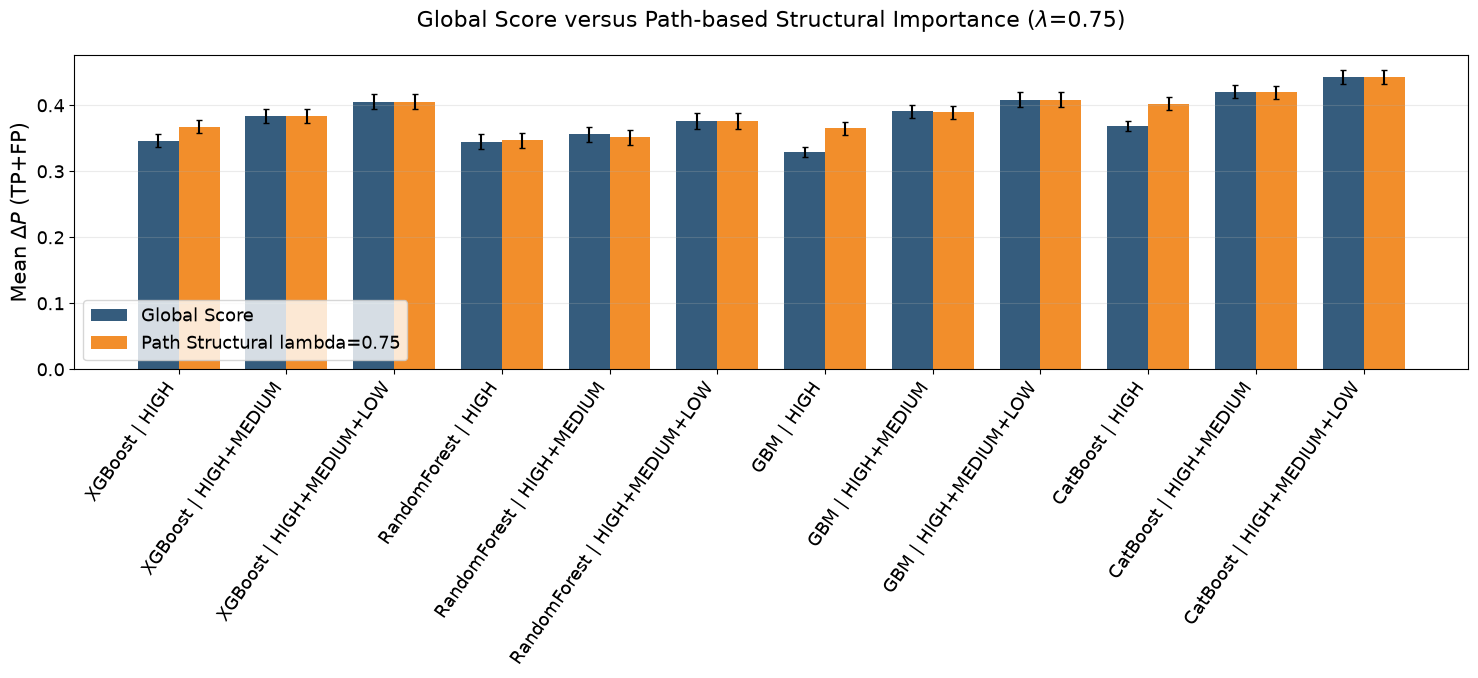

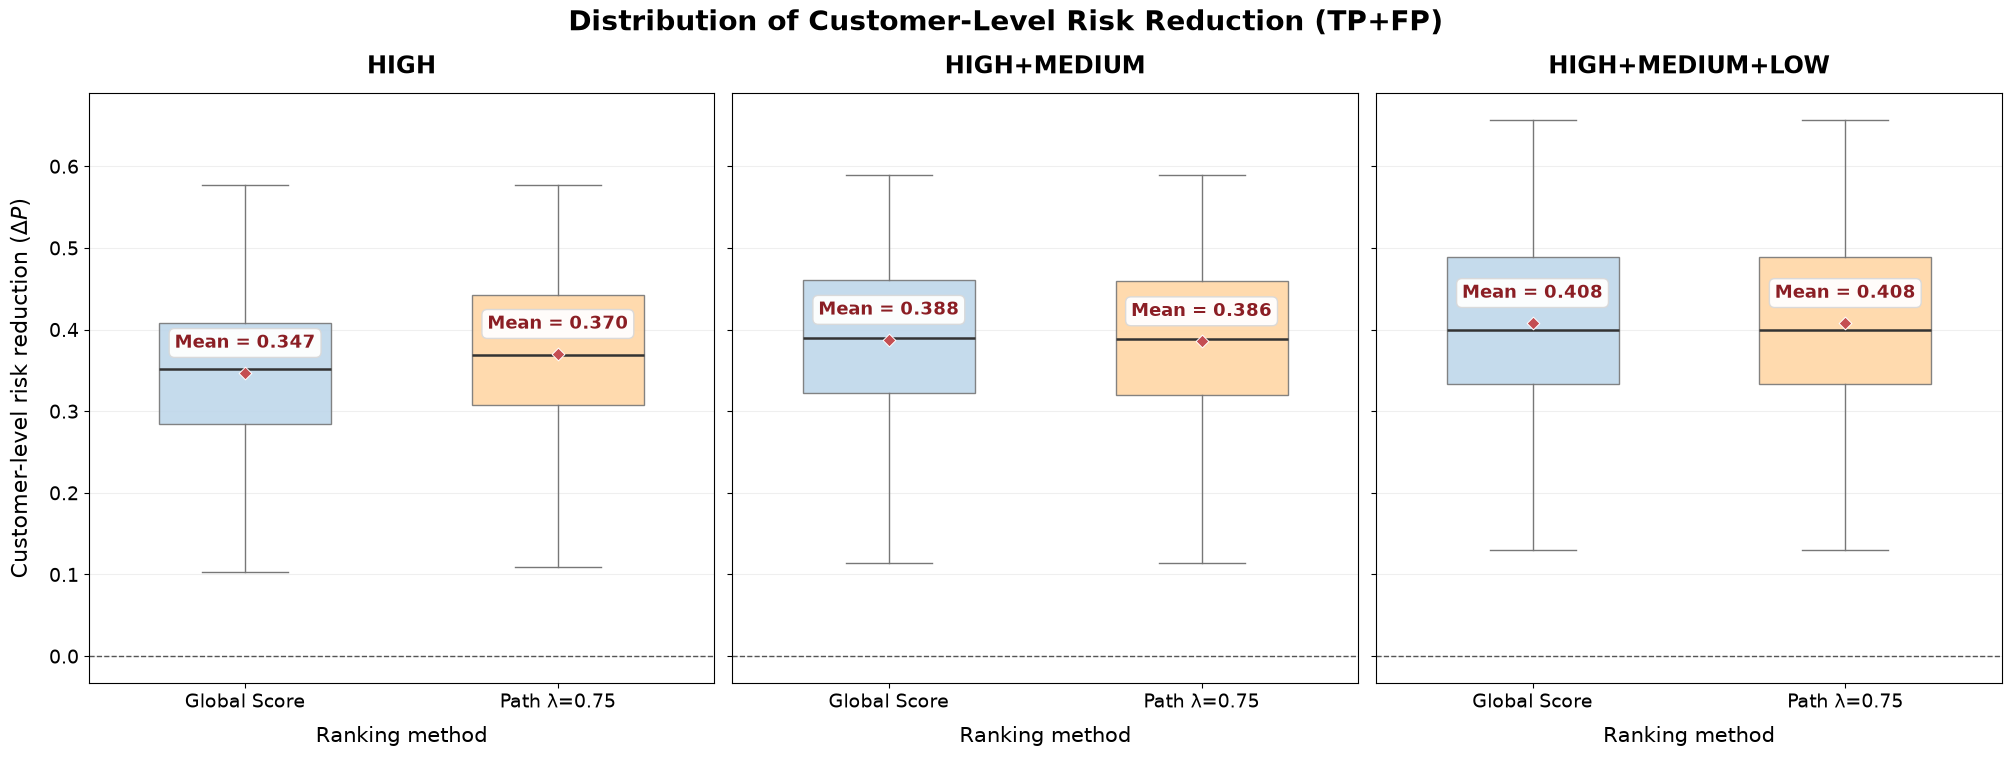

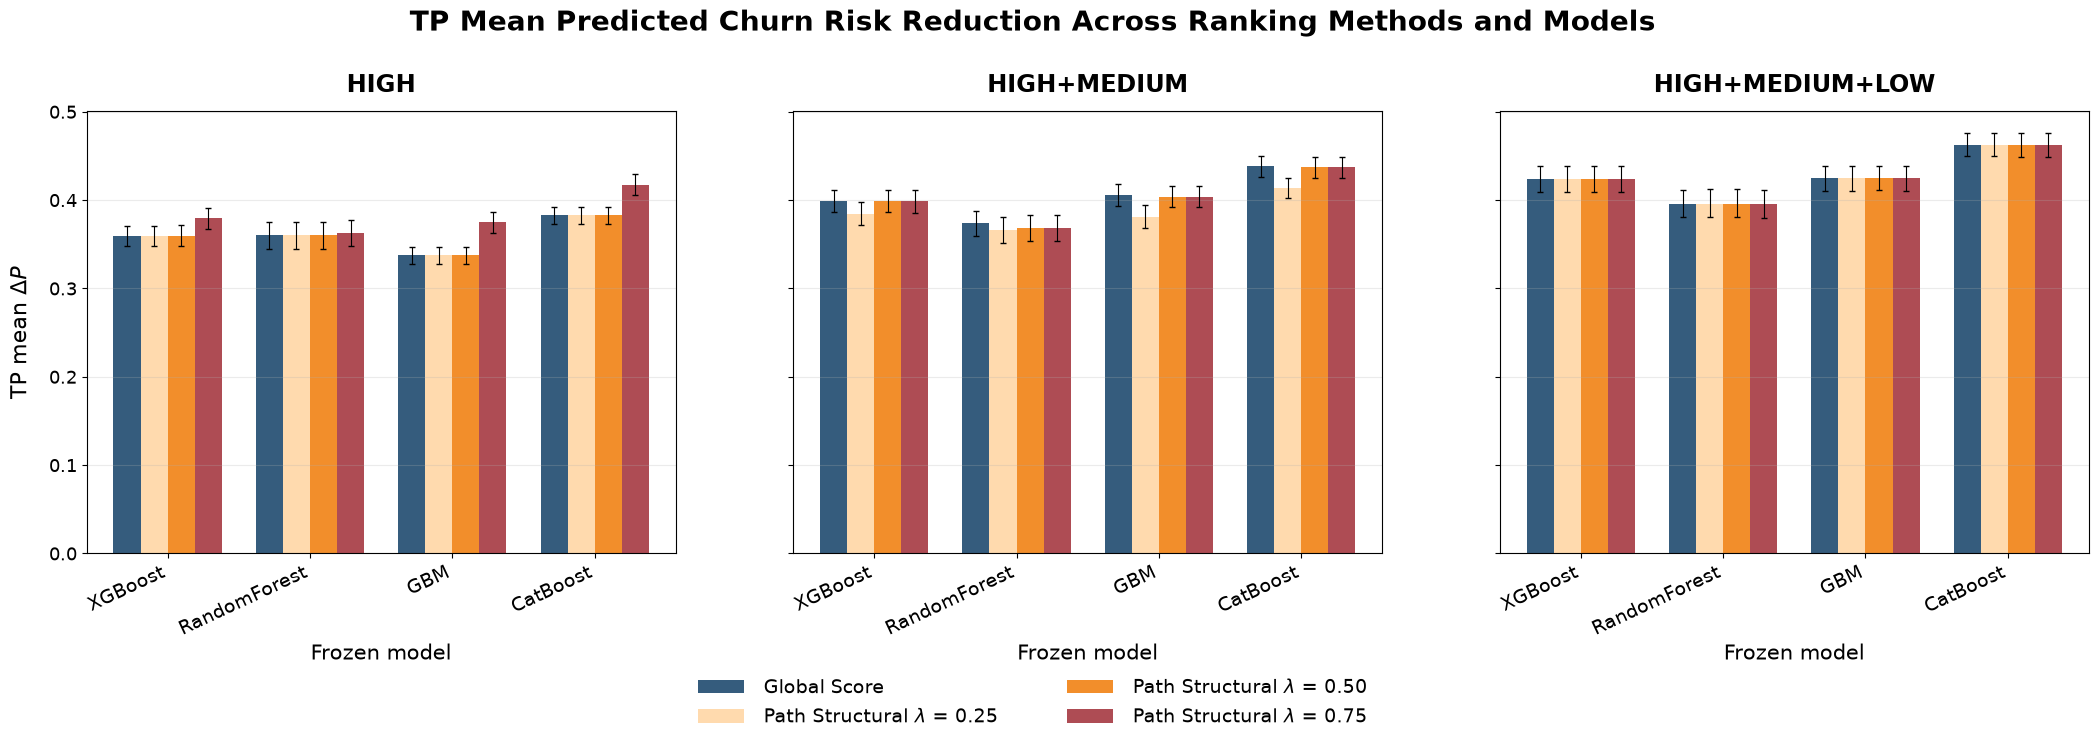

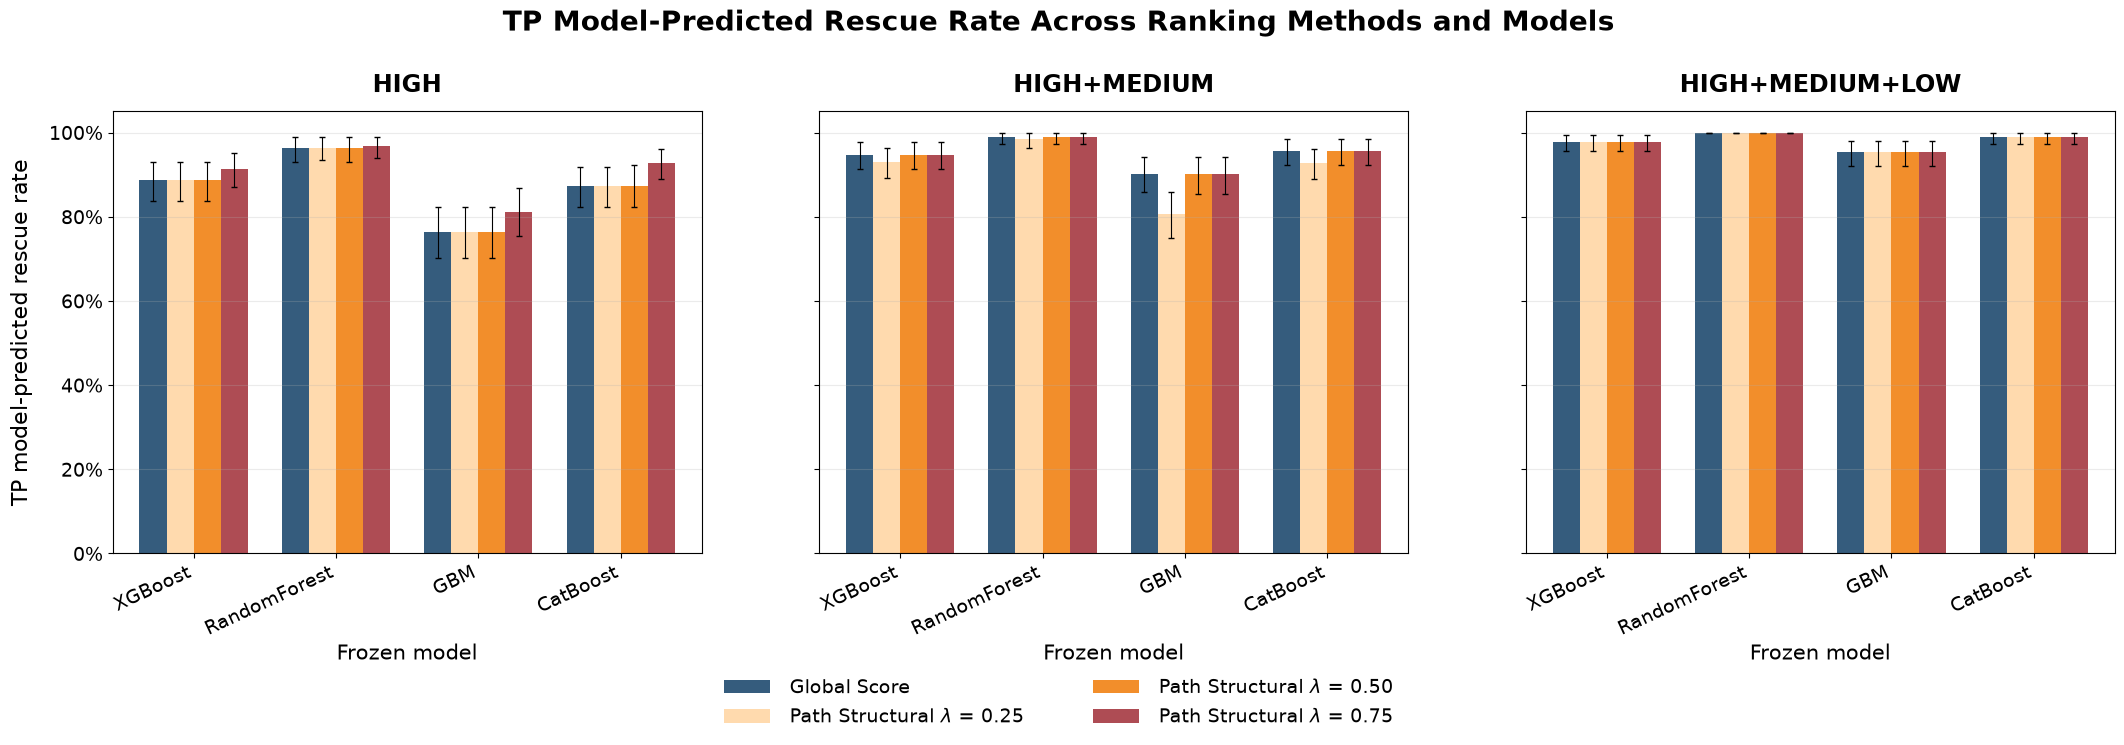

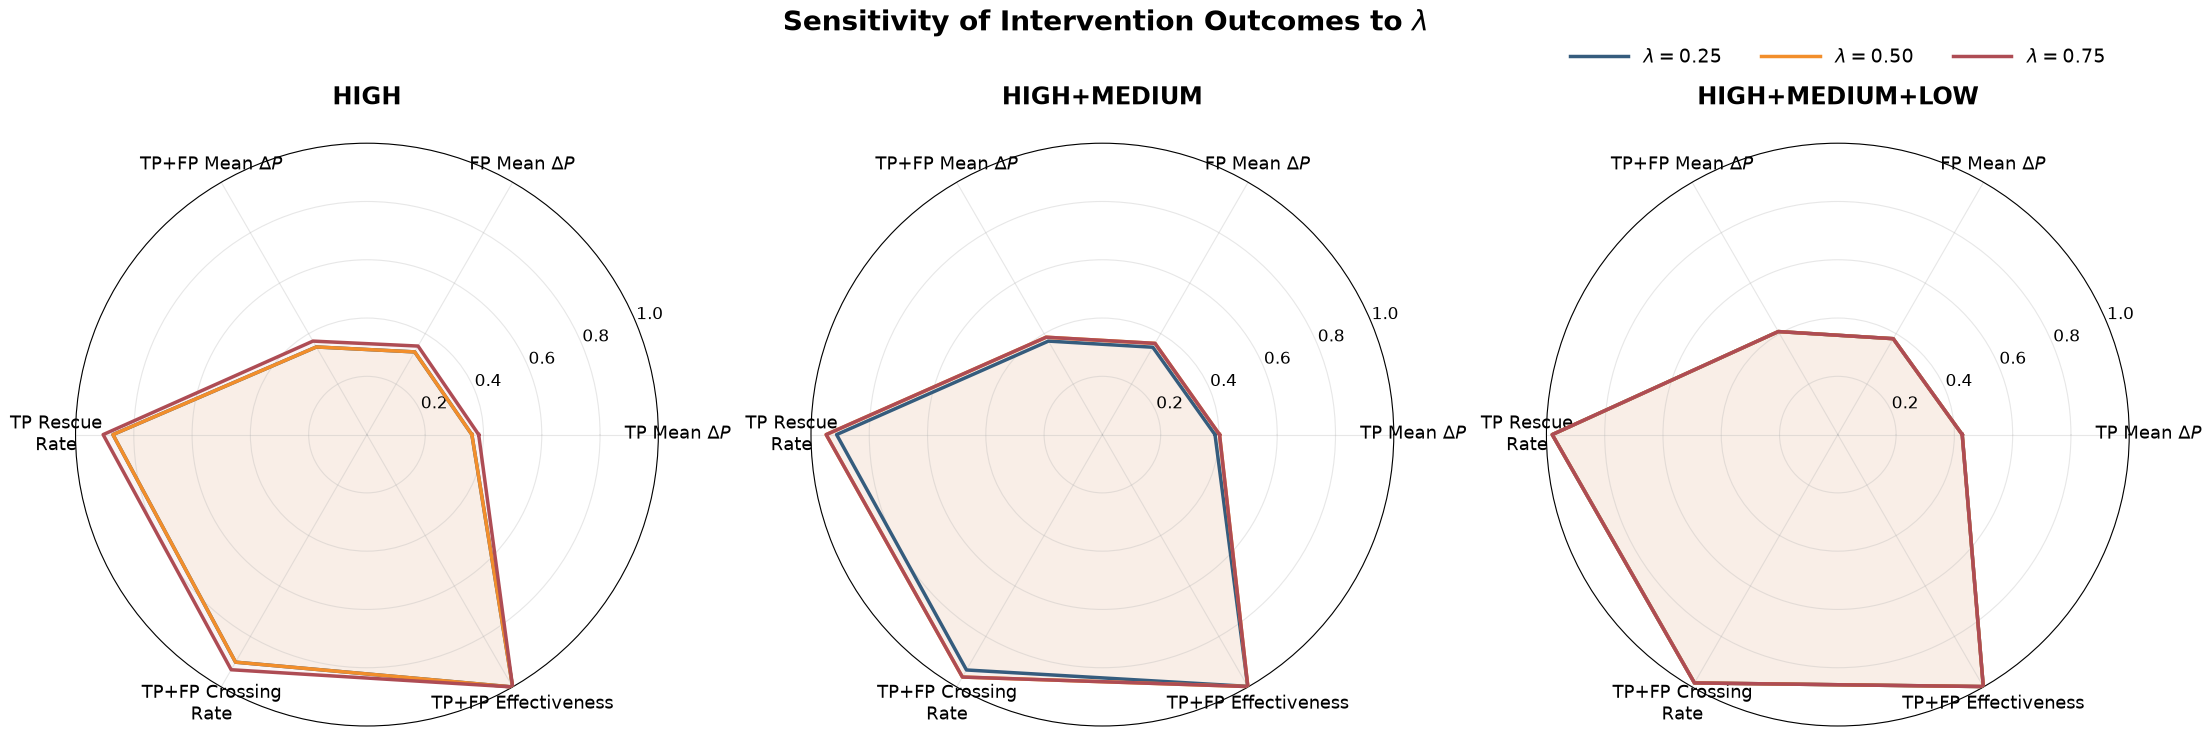

In [7]:
# Publication-oriented Matplotlib typography
plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 15,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 13,
    "figure.titlesize": 18,
})

# Figure 1: Global Score versus lambda=0.75, TP+FP mean DeltaP.
plot = descriptive_df[
    descriptive_df["Cohort"].eq("TP+FP")
    & descriptive_df["Strategy"].isin(["Global Score", COMPARISON_PATH_STRATEGY])
].copy()
plot["Label"] = plot["Model"] + " | " + plot["Scenario"]
labels = [f"{m} | {s}" for m in MODEL_ORDER for s in SCENARIO_ORDER]
x = np.arange(len(labels))
width = .38
fig, ax = plt.subplots(figsize=(15, 7))
for offset, strategy, color in [(-width/2, "Global Score", "#355C7D"), (width/2, COMPARISON_PATH_STRATEGY, "#F28E2B")]:
    part = plot[plot["Strategy"] == strategy].set_index("Label").loc[labels]
    y = part["Mean_Delta_P"].to_numpy()
    err = np.vstack([y - part["Mean_Delta_P_CI95_Lower"].to_numpy(), part["Mean_Delta_P_CI95_Upper"].to_numpy() - y])
    ax.bar(x + offset, y, width, label=strategy, color=color, yerr=err, capsize=2)
ax.set_xticks(x, labels, rotation=55, ha="right")
ax.set_ylabel(r"Mean $\Delta P$ (TP+FP)")
ax.set_title("Global Score versus Path-based Structural Importance ($\lambda$=0.75)",pad=20)
ax.legend(); ax.grid(axis="y", alpha=.25)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "GlobalScore_vs_PathStructural_lambda075_600dpi.png", dpi=600, bbox_inches="tight")
plt.show()

# Figure 2: TP+FP empirical DeltaP distributions for Global and lambda=0.75.
dist = analysis_df[
    analysis_df["Cohort"].eq("TP+FP")
    & analysis_df["Strategy"].isin(["Global Score", COMPARISON_PATH_STRATEGY])
].copy()

#fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True, constrained_layout=True)
fig, axes = plt.subplots(
    1,
    3,
    figsize=(20, 7),
    sharey=True,
    constrained_layout=True
)

box_colors = ["#BFD7EA", "#FFD6A5"]

for ax, scenario in zip(axes, SCENARIO_ORDER):
    data = [dist[(dist.Scenario == scenario) & (dist.Strategy == strategy)]["Delta_P_Churn"].to_numpy() for strategy in ["Global Score", COMPARISON_PATH_STRATEGY]]
    # Matplotlib >= 3.9 renamed the box-label argument to tick_labels.
    boxplot = ax.boxplot(
        data,
        tick_labels=[
            "Global Score",
            "Path λ=0.75"
        ],
        showfliers=False,
        patch_artist=True,
        widths=0.55,
        medianprops={
            "color": "#333333",
            "linewidth": 1.8
        },
        whiskerprops={
            "color": "#777777"
        },
        capprops={
            "color": "#777777"
        }
    )

    for patch, color in zip(
        boxplot["boxes"],
        box_colors
    ):
        patch.set_facecolor(color)
        patch.set_edgecolor("#777777")
        patch.set_alpha(0.90)

    # Add numerical means.
    means = [
        float(np.mean(values))
        if len(values)
        else np.nan
        for values in data
    ]

    for position, mean_value in enumerate(
        means,
        start=1
    ):
        if np.isfinite(mean_value):

            # Mean marker
            ax.scatter(
                position,
                mean_value,
                marker="D",
                s=42,
                color="#C44E52",
                edgecolor="white",
                linewidth=0.7,
                zorder=4
            )

            # Numerical mean value
            ax.annotate(
                f"Mean = {mean_value:.3f}",
                xy=(position, mean_value),
                xytext=(0, 15),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=13,
                fontweight="bold",
                color="#8B1E24",
                bbox={
                    "boxstyle": "round,pad=0.30",
                    "facecolor": "white",
                    "edgecolor": "#D9D9D9",
                    "alpha": 0.95
                }
            )

    ax.axhline(
        0,
        color="#555555",
        linewidth=1,
        linestyle="--"
    )

    ax.set_title(
        scenario,
        fontsize=17,
        fontweight="bold",
        pad=14
    )

    ax.set_xlabel(
        "Ranking method",
        fontsize=15,
        labelpad=10
    )
    
    ax.grid(
        axis="y",
        alpha=0.20
    )

    ax.tick_params(
        axis="x",
        labelsize=14
    )

    ax.tick_params(
        axis="y",
        labelsize=14
    )

axes[0].set_ylabel(
    r"Customer-level risk reduction ($\Delta P$)",
    fontsize=16,
    labelpad=12
)

fig.suptitle(
    "Distribution of Customer-Level Risk Reduction (TP+FP)",
    fontsize=20,
    fontweight="bold",
    y=1.06
)

fig.savefig(
    FIGURE_DIR / "DeltaP_Distribution_Global_vs_Path075_600dpi.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# Figure 3: all four methods x all four models - TP mean DeltaP.
method_colors = {
    "Global Score": "#355C7D",
    "Path Structural lambda=0.25": "#F28E2B",
    "Path Structural lambda=0.50": "#59A14F",
    "Path Structural lambda=0.75": "#B07AA1",
}

#"#FEF3C7"  # very light yellow
#"#FDE68A"  # light yellow
#"#FCD34D"  # stronger yellow

method_colors = {
    "Global Score": "#9ECAE1",
    "Path Structural lambda=0.25": "#FDD0A2",
    "Path Structural lambda=0.50": "#A1D99B",
    "Path Structural lambda=0.75": "#D4B9DA",
}

method_colors = {
    "Global Score": "#9ECAE1",
    "Path Structural lambda=0.25": "#FDD0A2",
    "Path Structural lambda=0.50": "#A1D99B",
    "Path Structural lambda=0.75": "#FCD34D",
}

method_colors = {
    "Global Score": "#61C5B7",       # light turquoise
    "Path Structural lambda=0.25": "#F8C56F",  # light yellow/orange
    "Path Structural lambda=0.50": "#5B88EB",  # light blue
    "Path Structural lambda=0.75": "#FF8A70"   # light coral
}

method_colors = {
    "Global Score": "#355C7D",       # light turquoise
    "Path Structural lambda=0.25": "#FFDAAE",  # light yellow/orange
    "Path Structural lambda=0.50": "#F28E2B",  # light blue
    "Path Structural lambda=0.75": "#AE4C54"   # light coral
}

fig, axes = plt.subplots(
    1,
    3,
    figsize=(22, 8.5),
    sharey=True
)

fig.subplots_adjust(
    left=0.07,
    right=0.98,
    top=0.84,
    bottom=0.32,
    wspace=0.20
)

x = np.arange(len(MODEL_ORDER))
width = 0.19
offsets = np.linspace(-1.5 * width, 1.5 * width, len(STRATEGY_ORDER))
for ax, scenario in zip(axes, SCENARIO_ORDER):
    for offset, strategy in zip(offsets, STRATEGY_ORDER):
        part = descriptive_df[
            descriptive_df["Strategy"].eq(strategy)
            & descriptive_df["Scenario"].eq(scenario)
            & descriptive_df["Cohort"].eq("TP")
        ].set_index("Model").loc[MODEL_ORDER]
        y = part["Mean_Delta_P"].to_numpy()
        err = np.vstack([
            y - part["Mean_Delta_P_CI95_Lower"].to_numpy(),
            part["Mean_Delta_P_CI95_Upper"].to_numpy() - y,
        ])
        ax.bar(
            x + offset, y, width, label=strategy, color=method_colors[strategy],
            yerr=err, capsize=2, error_kw={"elinewidth": 0.8},
        )
    ax.set_xticks(
        x,
        MODEL_ORDER,
        rotation=25,
        ha="right",
        fontsize=14
    )
    
    ax.set_title(
        scenario,
        fontsize=17,
        fontweight="bold",
        pad=14
    )
    
    ax.set_xlabel(
        "Frozen model",
        fontsize=15,
        labelpad=3
    )
    
    ax.grid(axis="y", alpha=.25)
    
axes[0].set_ylabel(
    r"TP mean $\Delta P$",
    fontsize=16,
    labelpad=12
)

handles, labels = axes[-1].get_legend_handles_labels()

labels = [
    "Global Score",
    r"Path Structural $\lambda$ = 0.25",
    r"Path Structural $\lambda$ = 0.50",
    r"Path Structural $\lambda$ = 0.75"
]

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.095),
    ncol=2,
    frameon=False,
    fontsize=14,
    columnspacing=3.5,
    handlelength=2.4,
    handletextpad=1.0
)

fig.suptitle(
    "TP Mean Predicted Churn Risk Reduction Across Ranking Methods and Models",
    fontsize=20,
    fontweight="bold",
    y=0.96
)

fig.savefig(FIGURE_DIR / "Four_Methods_Four_Models_TP_Mean_DeltaP_600dpi.png", dpi=600, bbox_inches="tight")
plt.show()

# Figure 4: all four methods x all four models - TP rescue rate.

fig, axes = plt.subplots(
    1,
    3,
    figsize=(22, 8.5),
    sharey=True
)

fig.subplots_adjust(
    left=0.07,
    right=0.98,
    top=0.84,
    bottom=0.32,
    wspace=0.20
)

for ax, scenario in zip(axes, SCENARIO_ORDER):
    for offset, strategy in zip(offsets, STRATEGY_ORDER):
        part = descriptive_df[
            descriptive_df["Strategy"].eq(strategy)
            & descriptive_df["Scenario"].eq(scenario)
            & descriptive_df["Cohort"].eq("TP")
        ].set_index("Model").loc[MODEL_ORDER]
        y = part["Threshold_Crossing_Rate"].to_numpy()
        err = np.vstack([
            y - part["Threshold_Crossing_CI95_Lower"].to_numpy(),
            part["Threshold_Crossing_CI95_Upper"].to_numpy() - y,
        ])
        ax.bar(
            x + offset, y, width, label=strategy, color=method_colors[strategy],
            yerr=err, capsize=2, error_kw={"elinewidth": 0.8},
        )

    ax.set_xticks(
        x,
        MODEL_ORDER,
        rotation=25,
        ha="right",
        fontsize=14
    )
    
    ax.set_title(
        scenario,
        fontsize=17,
        fontweight="bold",
        pad=14
    )

    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", alpha=.25)
    ax.set_xlabel(
        "Frozen model",
        fontsize=15,
        labelpad=3
    )
    
    ax.tick_params(
        axis="y",
        labelsize=14
    )

axes[0].set_ylabel(
    "TP model-predicted rescue rate",
    fontsize=16,
    labelpad=12
)

handles, labels = axes[-1].get_legend_handles_labels()

labels = [
    "Global Score",
    r"Path Structural $\lambda$ = 0.25",
    r"Path Structural $\lambda$ = 0.50",
    r"Path Structural $\lambda$ = 0.75"
]

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.095),
    ncol=2,
    frameon=False,
    fontsize=14,
    columnspacing=3.5,
    handlelength=2.4,
    handletextpad=1.0
)

fig.suptitle(
    "TP Model-Predicted Rescue Rate Across Ranking Methods and Models",
    fontsize=20,
    fontweight="bold",
    y=0.96
)

from matplotlib.ticker import PercentFormatter

for ax in axes:
    ax.yaxis.set_major_formatter(
        PercentFormatter(
            xmax=1.0,
            decimals=0
        )
    )

fig.savefig(FIGURE_DIR / "Four_Methods_Four_Models_TP_Rescue_Rate_600dpi.png", dpi=600, bbox_inches="tight")
plt.show()

# Figure 5: lambda sensitivity radar charts, one panel per scenario.

RADAR_LINE_COLORS = {
    "Global Score": "#355C7D",
    "Path Structural lambda=0.25": "#D99B55",
    "Path Structural lambda=0.50": "#F28E2B",
    "Path Structural lambda=0.75": "#AE4C54",
}

RADAR_FILL_COLORS = {
    "Global Score": "#355C7D",
    "Path Structural lambda=0.25": "#FFDAAE",
    "Path Structural lambda=0.50": "#F28E2B",
    "Path Structural lambda=0.75": "#AE4C54",
}

radar_metrics = [
    (r"TP Mean $\Delta P$", "TP", "Mean_Delta_P"),
    (r"FP Mean $\Delta P$", "FP", "Mean_Delta_P"),
    (r"TP+FP Mean $\Delta P$", "TP+FP", "Mean_Delta_P"),
    ("TP Rescue Rate", "TP", "Threshold_Crossing_Rate"),
    ("TP+FP Crossing Rate", "TP+FP", "Threshold_Crossing_Rate"),
    ("TP+FP Effectiveness", "TP+FP", "Effectiveness_Rate"),
]

angles = np.linspace(0, 2*np.pi, len(radar_metrics), endpoint=False).tolist()
angles += angles[:1]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(22, 8),
    subplot_kw={"polar": True},
    constrained_layout=True
)

colors_line = ["#355C7D", "#F28E2B", "#AE4C54"]
colors_fill = ["#FFDAAE", "#F28E2B", "#AE4C54"]

for ax, scenario in zip(axes, SCENARIO_ORDER):
    for strategy, color_line, color_fill in zip(
        PATH_STRATEGIES,
        colors_line,
        colors_fill
    ):
        values = []

        for _, cohort, metric in radar_metrics:
            value = descriptive_df[
                (descriptive_df["Strategy"] == strategy)
                & (descriptive_df["Scenario"] == scenario)
                & (descriptive_df["Cohort"] == cohort)
            ][metric].mean()

            values.append(float(value))

        # Close the radar polygon
        values.append(values[0])

        ax.plot(
            angles,
            values,
            color=color_line,
            linewidth=2.5,
            label=rf"$\lambda = {float(strategy.split('=')[-1]):.2f}$",
            zorder=3,
        )

        ax.fill(
            angles,
            values,
            color=color_fill,
            alpha=0.05
        )
        
    radar_labels = [
    metric[0]
        for metric in radar_metrics
    ]
    
    radar_labels = [
    r"TP Mean $\Delta P$",
    r"FP Mean $\Delta P$",
    r"TP+FP Mean $\Delta P$",
    "TP Rescue\nRate",
    "TP+FP Crossing\nRate",
    "TP+FP Effectiveness",
]

    ax.set_xticks(
        angles[:-1],
        [metric[0] for metric in radar_metrics],
        fontsize=13
    )

    ax.set_xticklabels(
        radar_labels,
        fontsize=13
    )
                    
    ax.tick_params(
        axis="y",
        labelsize=12,
        pad=12
    )

    for label in ax.get_xticklabels():
        label.set_rotation(0)
    
    ax.set_ylim(0, 1); 
    #ax.set_title(scenario, pad=20); 
    ax.set_title(
        scenario,
        fontsize=17,
        fontweight="bold",
        pad=28
    )
    ax.grid(alpha=.3)
    
axes[-1].legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 1.10),
    ncol = 3,
    fontsize=14,
    frameon=False,
    handlelength=3.0
)

fig.suptitle(
    r"Sensitivity of Intervention Outcomes to $\lambda$",
    fontsize=20,
    fontweight="bold",
    y=1.03
)
fig.savefig(FIGURE_DIR / "Lambda_Sensitivity_Radar_600dpi.png", dpi=600, bbox_inches="tight")
plt.show()


## 6A. Cross-model robustness of the Path-Based advantage

For each model, scenario and cohort, compare the **model-specific mean** Delta P under Global Score and Path-Based (lambda=0.75). Positive paired differences favor Path-Based. Cross-model SD is descriptive $ddof=0$, **not** a customer-bootstrap confidence interval. The aggregate GS and PS means are unweighted across the four models. TP and TP+FP are reported separately.


Strategy,Cohort,Scenario,Model,GS_Mean_Delta_P,PS_Mean_Delta_P,PS_minus_GS
0,TP,HIGH,XGBoost,0.359595,0.379335,0.019739
1,TP,HIGH,RandomForest,0.360234,0.362263,0.002029
2,TP,HIGH,GBM,0.337819,0.374800,0.036981
3,TP,HIGH,CatBoost,0.382789,0.417321,0.034532
4,TP,HIGH+MEDIUM,XGBoost,0.398868,0.398619,-0.000249
5,TP,HIGH+MEDIUM,RandomForest,0.373622,0.368604,-0.005018
6,TP,HIGH+MEDIUM,GBM,0.405840,0.403977,-0.001863
7,TP,HIGH+MEDIUM,CatBoost,0.438086,0.436990,-0.001096
8,TP,HIGH+MEDIUM+LOW,XGBoost,0.423898,0.423898,0.000000
9,TP,HIGH+MEDIUM+LOW,RandomForest,0.396117,0.396117,0.000000


,Cohort,Scenario,Models,GS_Mean_Delta_P,PS_Mean_Delta_P,Mean_Advantage,SD_Advantage,Min_Advantage,Max_Advantage,Models_Favoring_PS,Models_Favoring_GS,Models_Tied
0,TP,HIGH,4,0.360109,0.383430,0.023320,0.013950,0.002029,0.036981,4,0,0
1,TP,HIGH+MEDIUM,4,0.404104,0.402047,-0.002056,0.001802,-0.005018,-0.000249,0,4,0
2,TP,HIGH+MEDIUM+LOW,4,0.426917,0.426917,0.000000,0.000000,0.000000,0.000000,0,0,4
3,TP+FP,HIGH,4,0.347248,0.370492,0.023244,0.013746,0.001700,0.036327,4,0,0
4,TP+FP,HIGH+MEDIUM,4,0.387688,0.385934,-0.001754,0.001618,-0.004431,-0.000168,0,4,0
5,TP+FP,HIGH+MEDIUM+LOW,4,0.408319,0.408319,0.000000,0.000000,0.000000,0.000000,0,0,4


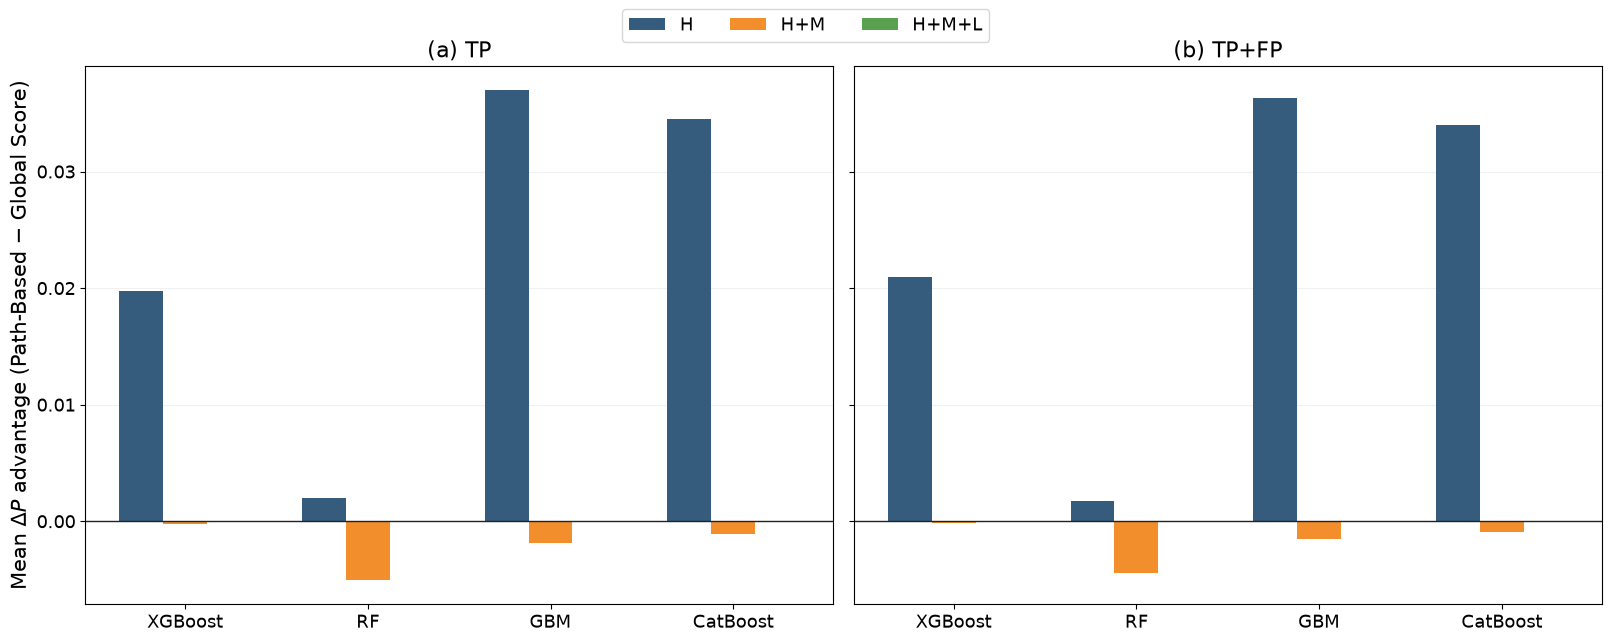

In [8]:
# Cross-model robustness: paired model-level mean differences
robust_source = descriptive_df[
    descriptive_df["Cohort"].isin(["TP", "TP+FP"])
    & descriptive_df["Strategy"].isin(["Global Score", COMPARISON_PATH_STRATEGY])
][["Cohort", "Scenario", "Model", "Strategy", "Mean_Delta_P"]].copy()

robust_pivot = robust_source.pivot(
    index=["Cohort", "Scenario", "Model"],
    columns="Strategy",
    values="Mean_Delta_P"
).reset_index()
if robust_pivot[["Global Score", COMPARISON_PATH_STRATEGY]].isna().any().any():
    raise ValueError("Incomplete GS / Path-Based pairs in cross-model robustness data.")
robust_pivot = robust_pivot.rename(columns={
    "Global Score": "GS_Mean_Delta_P",
    COMPARISON_PATH_STRATEGY: "PS_Mean_Delta_P"
})
robust_pivot["PS_minus_GS"] = robust_pivot["PS_Mean_Delta_P"] - robust_pivot["GS_Mean_Delta_P"]
robust_pivot["Model"] = pd.Categorical(robust_pivot["Model"], categories=MODEL_ORDER, ordered=True)
robust_pivot["Scenario"] = pd.Categorical(robust_pivot["Scenario"], categories=SCENARIO_ORDER, ordered=True)
robust_pivot["Cohort"] = pd.Categorical(robust_pivot["Cohort"], categories=["TP", "TP+FP"], ordered=True)
robust_detail_df = robust_pivot.sort_values(["Cohort", "Scenario", "Model"]).reset_index(drop=True)

robust_summary_df = robust_detail_df.groupby(
    ["Cohort", "Scenario"], observed=True, sort=False
).agg(
    Models=("Model", "nunique"),
    GS_Mean_Delta_P=("GS_Mean_Delta_P", "mean"),
    PS_Mean_Delta_P=("PS_Mean_Delta_P", "mean"),
    Mean_Advantage=("PS_minus_GS", "mean"),
    SD_Advantage=("PS_minus_GS", lambda x: np.std(x.to_numpy(float), ddof=0)),
    Min_Advantage=("PS_minus_GS", "min"),
    Max_Advantage=("PS_minus_GS", "max"),
    Models_Favoring_PS=("PS_minus_GS", lambda x: int((x > 1e-12).sum())),
    Models_Favoring_GS=("PS_minus_GS", lambda x: int((x < -1e-12).sum())),
    Models_Tied=("PS_minus_GS", lambda x: int((np.abs(x) <= 1e-12).sum())),
).reset_index()
if not (robust_summary_df["Models"] == len(MODEL_ORDER)).all():
    raise ValueError("Cross-model analysis requires all four models in each cohort/scenario.")

display(robust_detail_df)
display(robust_summary_df)

# Two-panel figure: TP and TP+FP, three intervention scenarios per model.
scenario_colors = {"HIGH": "#355C7D", "HIGH+MEDIUM": "#F28E2B", "HIGH+MEDIUM+LOW": "#59A14F"}
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True, constrained_layout=True)
positions = np.arange(len(MODEL_ORDER))
bar_width = 0.24
for ax, cohort in zip(axes, ["TP", "TP+FP"]):
    for j, scenario in enumerate(SCENARIO_ORDER):
        data = robust_detail_df[
            (robust_detail_df["Cohort"] == cohort) &
            (robust_detail_df["Scenario"] == scenario)
        ].set_index("Model").reindex(MODEL_ORDER)
        vals = data["PS_minus_GS"].to_numpy(float)
        ax.bar(positions + (j - 1)*bar_width, vals, width=bar_width,
               color=scenario_colors[scenario], label=scenario.replace("HIGH", "H").replace("MEDIUM", "M").replace("LOW", "L"))
    ax.axhline(0, color="#222222", linewidth=1)
    ax.set_xticks(positions, ["XGBoost", "RF", "GBM", "CatBoost"])
    ax.set_title("(a) TP" if cohort == "TP" else "(b) TP+FP")
    ax.grid(axis="y", alpha=0.18)
    ax.set_axisbelow(True)
axes[0].set_ylabel(r"Mean $\Delta P$ advantage (Path-Based $-$ Global Score)")
handles, _ = axes[0].get_legend_handles_labels()
fig.legend(handles, ["H", "H+M", "H+M+L"], loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.06))
fig.savefig(FIGURE_DIR / "CrossModel_PathBased_Advantage_TP_TPFP_600dpi.png",
            dpi=600, bbox_inches="tight", facecolor="white")
plt.show()


## 7. Export statistical results

In [ ]:
cross_model_summary_df = descriptive_df.groupby(
    ["Strategy", "Scenario", "Cohort"], as_index=False
).agg(
    Models=("Model", "nunique"),
    Mean_of_Model_Mean_Delta_P=("Mean_Delta_P", "mean"),
    Mean_Threshold_Crossing_Rate=("Threshold_Crossing_Rate", "mean"),
    Mean_Effectiveness_Rate=("Effectiveness_Rate", "mean"),
    Mean_Worsened_Rate=("Worsened_Rate", "mean"),
)

# Publication-oriented TP cross-model summary for all four methods.
cross_model_tp_summary_df = delta_p_statistics_df.groupby(
    ["Strategy", "Scenario"], as_index=False
).agg(
    Models=("Model", "nunique"),
    Mean_Rescue_Rate_Across_Models=("Rescue_Rate", "mean"),
    Min_Rescue_Rate=("Rescue_Rate", "min"),
    Max_Rescue_Rate=("Rescue_Rate", "max"),
    Mean_of_Model_Mean_Delta_P=("Mean_Delta_P", "mean"),
    Min_Model_Mean_Delta_P=("Mean_Delta_P", "min"),
    Max_Model_Mean_Delta_P=("Mean_Delta_P", "max"),
    Mean_of_Model_Median_Delta_P=("Median_Delta_P", "mean"),
    Min_Model_Median_Delta_P=("Median_Delta_P", "min"),
    Max_Model_Median_Delta_P=("Median_Delta_P", "max"),
    Total_Rescued_TP=("Rescued_TP_Count", "sum"),
    Total_TP_Evaluations=("TP_N", "sum"),
)
cross_model_tp_summary_df["Pooled_Rescue_Rate"] = (
    cross_model_tp_summary_df["Total_Rescued_TP"]
    / cross_model_tp_summary_df["Total_TP_Evaluations"]
)

# Complete four-method synthesis, averaged across the four frozen models.
synthetic_comparison_df = descriptive_df.groupby(
    ["Strategy", "Scenario", "Cohort"], as_index=False
).agg(
    Models=("Model", "nunique"),
    Mean_Delta_P=("Mean_Delta_P", "mean"),
    Median_Delta_P=("Median_Delta_P", "mean"),
    Threshold_Crossing_Rate=("Threshold_Crossing_Rate", "mean"),
    Effectiveness_Rate=("Effectiveness_Rate", "mean"),
    Worsened_Rate=("Worsened_Rate", "mean"),
)
synthetic_comparison_df["DeltaP_Rank_within_Scenario_Cohort"] = (
    synthetic_comparison_df.groupby(["Scenario", "Cohort"])["Mean_Delta_P"]
    .rank(method="min", ascending=False).astype(int)
)
synthetic_comparison_df["Crossing_Rank_within_Scenario_Cohort"] = (
    synthetic_comparison_df.groupby(["Scenario", "Cohort"])["Threshold_Crossing_Rate"]
    .rank(method="min", ascending=False).astype(int)
)

# Compact paper table for the operational TP+FP cohort.
paper_synthetic_tp_fp_df = synthetic_comparison_df[
    synthetic_comparison_df["Cohort"].eq("TP+FP")
].copy()
paper_synthetic_tp_fp_df["Method_Order"] = pd.Categorical(
    paper_synthetic_tp_fp_df["Strategy"], categories=STRATEGY_ORDER, ordered=True
)
paper_synthetic_tp_fp_df["Scenario_Order"] = pd.Categorical(
    paper_synthetic_tp_fp_df["Scenario"], categories=SCENARIO_ORDER, ordered=True
)
paper_synthetic_tp_fp_df = paper_synthetic_tp_fp_df.sort_values(
    ["Scenario_Order", "Method_Order"]
)[[
    "Strategy", "Scenario", "Models", "Mean_Delta_P", "Median_Delta_P",
    "Threshold_Crossing_Rate", "Effectiveness_Rate", "Worsened_Rate",
    "DeltaP_Rank_within_Scenario_Cohort", "Crossing_Rank_within_Scenario_Cohort",
]].reset_index(drop=True)

display(paper_synthetic_tp_fp_df)

# Import baseline diagnostics produced by the extended experiment notebook.
# These are descriptive test-set diagnostics, not additional intervention tests.
diagnostic_sheets = {
    "Calibration Metrics": "Calibration Metrics",
    "Calibration Bins": "Calibration Bins",
    "Threshold Comparison": "Threshold Comparison",
}
with pd.ExcelFile(INPUT_XLSX) as source_xls:
    missing_diagnostics = set(diagnostic_sheets) - set(source_xls.sheet_names)
    if missing_diagnostics:
        raise ValueError(
            f"Missing diagnostic sheets {sorted(missing_diagnostics)} in {INPUT_XLSX}. "
            "Run the extended 4.1 experiment notebook first."
        )
    diagnostic_data = {
        output_name: pd.read_excel(source_xls, sheet_name=source_name)
        for source_name, output_name in diagnostic_sheets.items()
    }

with pd.ExcelWriter(OUTPUT_XLSX, engine="openpyxl") as writer:
    descriptive_df.to_excel(writer, sheet_name="Bootstrap Descriptives", index=False)
    robust_detail_df.to_excel(writer, sheet_name="Path Advantage by Model", index=False)
    robust_summary_df.to_excel(writer, sheet_name="Path Advantage Summary", index=False)
    for sheet_name, diagnostics in diagnostic_data.items():
        diagnostics.to_excel(writer, sheet_name=sheet_name, index=False)
    delta_p_statistics_df.to_excel(writer, sheet_name="DeltaP Statistics", index=False)
    pairwise_df.to_excel(writer, sheet_name="Global vs Path Tests", index=False)
    interpretation_df.to_excel(writer, sheet_name="Test Interpretation", index=False)
    lambda_sensitivity_df.to_excel(writer, sheet_name="Lambda Friedman Tests", index=False)
    lambda_pairwise_df.to_excel(writer, sheet_name="Lambda Pairwise Tests", index=False)
    lambda_interpretation_df.to_excel(writer, sheet_name="Lambda Interpretation", index=False)
    cross_model_tp_summary_df.to_excel(writer, sheet_name="Cross-Model Summary", index=False)
    cross_model_summary_df.to_excel(writer, sheet_name="Cross-Model All Cohorts", index=False)
    paper_synthetic_tp_fp_df.to_excel(writer, sheet_name="Four-Method TP+FP Table", index=False)
    synthetic_comparison_df.to_excel(writer, sheet_name="Four-Method All Cohorts", index=False)
    analysis_df.to_excel(writer, sheet_name="Analysis Customer Level", index=False)

wb = load_workbook(OUTPUT_XLSX)
header_fill = PatternFill("solid", fgColor="1F4E78")
for ws in wb.worksheets:
    ws.freeze_panes = "A2"
    ws.auto_filter.ref = ws.dimensions
    for cell in ws[1]:
        cell.fill = header_fill
        cell.font = Font(bold=True, color="FFFFFF")
        cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
    for column in ws.columns:
        letter = column[0].column_letter
        ws.column_dimensions[letter].width = min(42, max(11, max(len(str(c.value or "")) for c in column) + 2))
wb.save(OUTPUT_XLSX)

print("Saved:", OUTPUT_XLSX)
print("Figures saved in:", FIGURE_DIR)


## Interpretation 

- Positive $\Delta P$ means the simulated intervention lowers predicted churn risk.
- Threshold crossing is stricter than effectiveness: a customer can have positive
  $\Delta P$ without crossing below the frozen classification threshold.
- TP results evaluate predicted rescue among actual churners correctly detected at
  baseline. FP results diagnose how interventions affect high-risk false alarms.
- TP+FP matches the operational high-risk cohort and is directly comparable to studies
  evaluating all customers above the decision threshold.
- Lambda sensitivity indicates how strongly path-length discounting changes predictive
  intervention outcomes.
- Every reported effect remains a frozen-model predictive simulation, not an observed
  real-world treatment effect.
